
<div style="background-color: lightgreen; color: black; padding: 20px; box-sizing: border-box; width: 99%;">

👋 <b>¡Hola! Soy Dot, tu revisor IA.</b>

🎉 <b>¡Felicidades! Has aprobado tu proyecto.</b>

¡Excelente trabajo al completar esta tarea! Ahora utilizas la prueba t de Welch de forma consistente, la verificación de Levene reporta la conclusión correcta y tu resumen ejecutivo presenta el estadístico actualizado con cifras claras y una redacción cautelosa. Para futuros proyectos, concéntrate en imprimir valores p muy pequeños en un formato que no muestre 0.0000, en redactar con precisión las interpretaciones de los valores p y en revisar cuidadosamente tu texto. ¡Sigue con ese gran trabajo analítico!

Si experimentas alguna dificultad o error, no dudes en contactar a nuestro equipo de soporte haciendo clic en el ícono de chat en la esquina superior derecha o escribiéndonos a [helpme@tripleten.com](mailto:helpme@tripleten.com).

<hr style="margin-top: 20px; margin-bottom: 20px;">

<details>
<summary><b style="cursor: pointer;">💡 Haz clic aquí para ver cómo leer mis comentarios (Leyenda de colores)</b></summary>
<div style="margin-top: 15px;">
A continuación encontrarás mis comentarios. <b>Te pido amablemente que no los muevas, modifiques ni elimines</b>.

Puedes encontrar mis comentarios resaltados en recuadros verdes, amarillos o rojos como estos:

<div class="alert alert-block alert-success">
Éxito. Todo se ha realizado correctamente.
</div>

<div class="alert alert-block alert-warning">
Observaciones. Algunas recomendaciones.
</div>

<div class="alert alert-block alert-danger">
Por corregir. El bloque requiere algunas correcciones.
</div>
</div>
</details>

</div>


# Experimento A/B en página de inicio

El objetivo de este proyecto es evaluar un **experimento A/B** realizado en una página de inicio (landing page) con versiónes **A y B** para apoyar una **decisión de negocio basada en datos**.

---

El archivo `landing_experiment.csv` contiene información de usuarios expuestos a dos versiones de la página de inicio (landing page) dentro del experimento A/B. Incluye región, dispositivo, fuente de tráfico, tipo de usuario, conversión y gasto.

El análisis sigue una lógica clara y progresiva:

1. 🔍 Explorar y validar los datos.

2. 💰 Comparar el **gasto promedio** por usuario entre la página A y B.

3. 🎯 Comparar la **tasa de conversión** entre la página A y B.

4. 🌐 Revisar **la relación entre la fuente de tráfico y la conversión**.

5. 👤 Revisar **la relación entre el tipo de usuario y la conversión**.

6. 📈 **Visualizar los resultados**: Respalda tus conclusiones mediante gráficos claros.

Se aplican **puebas estadísticas apropiados** para comparar las páginas y **recomendar qué versión es mejor**, justificando la decisión con datos.

## 🧩 Paso 1: Cargar y validar los datos

### 1.1 Carga de datos y vista rápida

In [1]:
# importar librerías
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 


from scipy.stats import ttest_ind
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import chi2_contingency
from scipy.stats import levene

In [2]:
# cargar archivo
df = pd.read_csv('/datasets/landing_experiment.csv')

**Vista previa e información general del conjunto de datos**

In [3]:
# Se define la columna date como fecha. 
df['date'] = pd.to_datetime(df['date'])

# mostrar las primeras 5 filas
df.head()


,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


<div class="alert alert-block alert-success">

Buen trabajo al convertir `date` a un tipo datetime real justo después de cargar los datos. El comentario sobre la conversión explica el motivo, y la salida de `df.info()` confirma el tipo (`datetime64[ns]`), por lo que tus verificaciones posteriores de rangos de fechas son fiables.

</div>

In [4]:
# información general
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   user_id         40000 non-null  object        
 1   date            40000 non-null  datetime64[ns]
 2   landing         40000 non-null  object        
 3   region          40000 non-null  object        
 4   dispositivo     40000 non-null  object        
 5   traffic_source  40000 non-null  object        
 6   user_type       40000 non-null  object        
 7   converted       40000 non-null  int64         
 8   gasto           40000 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(6)
memory usage: 2.7+ MB


Se trata de un data set concistente con 40000 regstros sin presencia de nulos en las variables.

<div class="alert alert-block alert-warning">

Tu lectura es correcta: 40,000 filas y ningún valor nulo. Dos mejoras opcionales: (1) mencionar los tipos de las columnas y que se ajustan a cada variable, por ejemplo, `date` ahora es datetime, `converted` es un entero, `gasto` es un float y el resto son categóricas; (2) corregir los errores tipográficos 'concistente' -> 'consistente', 'regstros' -> 'registros' y 'data set' -> 'dataset'.

</div>

**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


 **Variable `user_id`**  
 Verificar usuarios únicos

In [5]:
# Verificación de dúplicados
df['user_id'].duplicated().sum()

0

 **Variable `date`**  
Explorar rango de fechas

In [6]:
# Resumen estadístico
df["date"].describe()

count                   40000
unique                     28
top       2026-01-24 00:00:00
freq                     1512
first     2026-01-01 00:00:00
last      2026-01-28 00:00:00
Name: date, dtype: object

In [7]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01 00:00:00
Fecha máxima: 2026-01-28 00:00:00


**Variable `gasto` (numérica)**

In [8]:
# Resumen estadístico
df['gasto'].describe()


count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

In [9]:
# Resumen estadístico de usuarios que se convirtieron
df_converted = df[df['converted'] == 1]
df_converted.describe()

,converted,gasto
count,5706.0,5706.000000
mean,1.0,65.373668
std,0.0,30.896545
min,1.0,12.120000
25%,1.0,42.950000
50%,1.0,59.860000
75%,1.0,80.370000
max,1.0,303.680000


 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [10]:
# Explorar variables categóricas y cómo se distribuyen
df_object = df.select_dtypes(include=['object'])

print("\nConteo de categorías:")
for col in df_object.columns[1:]:
    display(df_object[col].value_counts())
    print()


Conteo de categorías:


B    20018
A    19982
Name: landing, dtype: int64

Norte        11166
Centro        9613
Sur           8039
Occidente     6398
Oriente       4784
Name: region, dtype: int64

Mobile     24829
Desktop    15171
Name: dispositivo, dtype: int64

Organic     17987
Ads         11935
Email        6123
Referral     3955
Name: traffic_source, dtype: int64

Nuevo         26033
Recurrente    13967
Name: user_type, dtype: int64

In [11]:
# Valores únicos
for i in df.select_dtypes(include='object').columns[1:]:
    print(10*'-','Valores Únicos' , 10*'-','\n')
    print(f'{i}:')
    print(*df[i].unique())
    
    

---------- Valores Únicos ---------- 

landing:
A B
---------- Valores Únicos ---------- 

region:
Norte Occidente Centro Sur Oriente
---------- Valores Únicos ---------- 

dispositivo:
Mobile Desktop
---------- Valores Únicos ---------- 

traffic_source:
Email Organic Ads Referral
---------- Valores Únicos ---------- 

user_type:
Recurrente Nuevo


- Todas las columnas tienen los valores esperados

## 💰 Paso 2: Comparar el gasto promedio por usuario (página A vs B)

Se evalua si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.


In [12]:
# Gasto por versión
df_A = df_converted[df_converted['landing'] == 'A'] 
df_B = df_converted[df_converted['landing'] == 'B'] 

# Verificar cantidad de datos que tiene cada grupo
len(df_A), len(df_B)

(2512, 3194)

### Prueba t-Welch

**Hipótesis:**
- **Hipótesis nula (H₀):** El gasto promedio por usuario en la *Landing* A es igual al de la *Landing* B. No hay una diferencia significativa.
- **Hipótesis alternativa (H₁):** El gasto promedio por usuario *Landing* A y la *landing* B es estadísticamente diferente

Se utiliza la prueba t-Welch para la comparación de los promedios de una variable numérica continua entre dos grupos independientes

<div class="alert alert-block alert-warning">

Corregiste el problema principal: esta sección ahora nombra la prueba t de Welch, lo cual coincide con el título de la sección y con la prueba `equal_var=False` que ejecutas más adelante. Para completarla, agrega la razón por la que elegiste Welch, por ejemplo: 'No asume varianzas iguales, lo cual es adecuado porque la prueba de Levene indica que las varianzas de A y B son diferentes.' Opcional: enuncia la hipótesis alternativa completa ('el gasto promedio por usuario convertido en A es diferente al de B') y corrige 'estadisticamente' -> 'estadísticamente'.

</div>

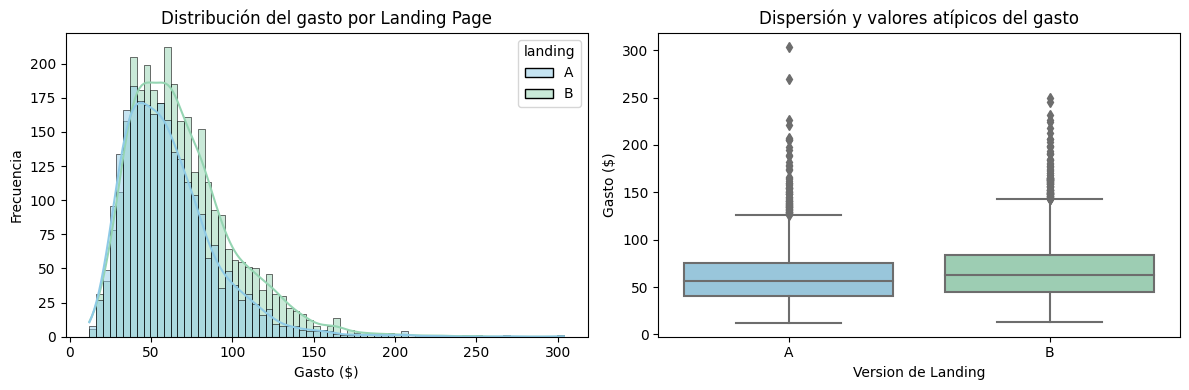

Estadístico Levene: 29.1765
P-Valor de Levene: 0.0000
Se rechaza la hipotesis nula hay evidencia de varianzas diferentes (equal_var=False).


In [13]:

# Revison del gasto 
gasto_A = df_A['gasto']
gasto_B = df_B['gasto']

# Verificación visual de la distribución
fig, ax = plt.subplots(1,2, figsize=(12,4))

sns.histplot(
    data=df[df['converted']>0],
    x='gasto',
    hue='landing',
    kde=True,
    ax=ax[0],
    palette=["#8ecae6", "#95d5b2"]
)

ax[0].set_title('Distribución del gasto por Landing Page')
ax[0].set_xlabel('Gasto ($)')
ax[0].set_ylabel('Frecuencia')

sns.boxplot(
    data=df[df['converted']>0],
    x='landing',
    y='gasto',
    ax=ax[1],
    palette=['#8ecae6', '#95d5b2']
)

plt.title('Dispersión y valores atípicos del gasto')
plt.xlabel('Version de Landing')
plt.ylabel('Gasto ($)')

plt.tight_layout()
plt.show()

# Verificación de igualdad de varianza (Prueba Levene)
stat_levene, p_levene = levene(gasto_A, gasto_B)

print(f'Estadístico Levene: {stat_levene:.4f}')
print(f'P-Valor de Levene: {p_levene:.4f}')


# Definición de la prueba
alpha = 0.05

if p_levene < alpha:
    print('Se rechaza la hipotesis nula hay evidencia de varianzas diferentes (equal_var=False).')
else:
    print('No se rechaza la hipotesis nula, no hay evidencia estadistica suficiente de varianzas diferentes.')



<div class="alert alert-block alert-warning">

Buena corrección: la prueba de Levene ahora usa `p_levene < alpha`, así que el mensaje impreso informa correctamente que hay evidencia de varianzas diferentes y concuerda con tu sección de supuestos y con la prueba de Welch. Tu histograma y tu boxplot muestran claramente el sesgo a la derecha, los valores atípicos y la mayor dispersión de B. Una mejora rápida: el valor p todavía se imprime como `0.0000`, lo que oculta su magnitud. Imprímelo con `{p_levene:.4g}` o `{p_levene:.2e}` para que el lector vea que es muy pequeño pero no exactamente cero. También podrías pulir el mensaje impreso (acentos y puntuación), por ejemplo: 'Se rechaza H0: hay evidencia de varianzas diferentes (se usa equal_var=False).'

</div>

### Revisión de los supuestos 

##### Normalidad y Tamaño Muestral 
Las visualizaciones confirman que la distribución del gasto presenta un marcado sesgo positivo hacia la derecha en ambas versiones, con valores atípicos que superan los 200. No obstante, dado el gran tamaño muestral de ambos grupos ($n_A = 2,512$ y $n_B = 3,194$), el Teorema del Límite Central garantiza que la distribución de las medias muestrales tiende a la normalidad, haciendo válida la aplicación de la prueba paramétrica.

##### Homogeneidad de la varianza
Tanto la mayor amplitud de la caja y los bigotes de la versión B en el boxplot como la prueba formal de Levene ($p < 0.05$) indican que se rechaza la hipótesis nula de igualdad de varianzas, existiendo evidencia estadística de que las dispersiones de ambos grupos son diferentes. Por lo tanto, no se cumple el supuesto de homocedasticidad y resulta apropiado utilizar la prueba t de Welch (equal_var=False) para comparar los promedios sin asumir varianzas iguales

<div class="alert alert-block alert-success">

Tu sección de supuestos está bien razonada. Justificas la normalidad con el Teorema del Límite Central usando tus tamaños de muestra (2,512 y 3,194), interpretas correctamente la prueba de Levene y la respaldas con la caja y los bigotes más amplios de B. Luego concluyes que Welch es la prueba adecuada.

</div>

In [14]:
# Se definen los grupos para la prueba
A =  df[(df['converted'] == 1) & (df['landing']=='A')]['gasto']
B =  df[(df['converted'] == 1) & (df['landing']=='B')]['gasto']

print('Promedios')
display(f'Gasto promedio de la Landing A: {A.mean().round(2)}')
display(f'Gasto promedio de la Landing B: {B.mean().round(2)}')
print('')

# Aplicar prueba
t_stat, p_value = ttest_ind(A, B, equal_var=False)

# Visualizar resultados
print(f"Estadístico: {t_stat}")
print(f"Valor p:      {p_value}")
print('')

# interpretación
alpha = 0.05 # Umbra de significancia

if p_value < alpha:
    print('Se rechaza la hipotesis nula: Hay evidencia de una diferencia.')
else:
    print('No rechazamos la hipotesis nula: No hay evidencia suficiente de una diferencia.')




Promedios


'Gasto promedio de la Landing A: 61.09'

'Gasto promedio de la Landing B: 68.75'


Estadístico: -9.48101092267275
Valor p:      3.627602231521493e-21

Se rechaza la hipotesis nula: Hay evidencia de una diferencia.


### 📝 Conclusión e interpretación

**Decisión:**  

Se rechaza la hipótesis nula ($H_0$). El $p$-valor obtenido ($p < 0.001$) es drásticamente inferior al nivel de significancia establecido ($\alpha = 0.05$), lo que proporciona evidencia estadística sólida en contra de $H_0$ y respalda que el gasto promedio difiere significativamente entre la Landing A y la Landing B

**Interpretación de negocio:**  
Los resultados de la prueba t-Welch ofrece evidencia estadística solida ($p < 0.001$, $t = -9.48$) que la Landing B genera un mayor gasto promedio por usuario convertido. En B cada usuario conevertido 68.75  frete a un 61.09 en A  El signo negativo del estadístico $t$ confirma que la facturación promedio de la página A es inferior a la de la página B, representando una brecha positiva, por cada cliente adquirido en la versión B. Para el negocio, esto significa que la Landing B no solo convierte usuarios, sino que logra monetizar mejor cada transacción. 

<div class="alert alert-block alert-warning">

Tu decisión (rechazar H₀) es correcta, y actualizaste el estadístico a t = -9.48, que ahora coincide con tu resultado de Welch. La interpretación de negocio apunta en la dirección correcta, pero la oración clave todavía necesita pulirse: corrige 'ofrece' -> 'ofrecen', 'solida' -> 'sólida', 'conevertido' -> 'convertido' y 'frete' -> 'frente', y agrega la puntuación que falta. Además, elimina la frase confusa 'representando una brecha positiva, por cada cliente adquirido en la versión B', ya que la oración anterior ya lo dice. Cuantifica la brecha (aproximadamente 7.66 más por usuario convertido, cerca de +12.5%) y menciona que esta comparación solo incluye a los usuarios que se convirtieron.

</div>

---


## 📈 Paso 3: Comparar la tasa de conversión entre la página A y B

Se evalua si existen diferencias bilaterales y estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.

### Prueba Z de proporciones o Z-test

**Hipótesis:**
- **Hipótesis nula (H₀):** La tasa de conversion de la *Landing* A es igual a la tasa de conversión de la *landing* B. No hay diferencia significativa.
- **Hipótesis alternativa (H₁):** La tasa de conversión de la *landing* A y la landing B es estadísticamente diferente.
  

In [15]:
# Número de usuarios convertidos por página
conversiones = df.groupby('landing')['converted'].sum()
totales = df.groupby('landing')['converted'].count()

print('Conversiones por página')
display(conversiones)
print('')

print('Usuarios totales por página')
display(totales)
print('')


print('Tasa de conversion')
display((conversiones / totales * 100).round(2) )
print('')

# Exitos vs observaciones
exitos = [conversiones['A'], conversiones['B']]
observaciones = [totales['A'], totales['B']]

# Aplicar prueba y visualizar resultados
z_stat, p_value = proportions_ztest(exitos, observaciones)
print('Resultados de la prueba')
print("Estadístico Z:", z_stat)
print("Valor p:", p_value)
print('')
# interpretación
alpha = 0.05 # Umbral de significancia

if p_value < alpha:
    print('Se rechaza la hipotesis nula: Hay evidencia de una diferencia.')
else:
    print('No rechazamos la hipotesis nula: No hay evidencia suficiente de una diferencia.')


Conversiones por página


landing
A    2512
B    3194
Name: converted, dtype: int64


Usuarios totales por página


landing
A    19982
B    20018
Name: converted, dtype: int64


Tasa de conversion


landing
A    12.57
B    15.96
Name: converted, dtype: float64


Resultados de la prueba
Estadístico Z: -9.677362674655983
Valor p: 3.7629765627523803e-22

Se rechaza la hipotesis nula: Hay evidencia de una diferencia.


<div class="alert alert-block alert-success">

Este es un bloque bien construido. Calculas las conversiones y los totales por página con `groupby` y muestras las tasas (12.57% vs. 15.96%), de modo que el lector puede ver los datos detrás de Z ≈ -9.68. Pasas correctamente los éxitos y las observaciones a `proportions_ztest`, aplicas la regla de decisión con α = 0.05 y las etiquetas de tu salida son claras.

</div>

### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipótesis nula ($H_0$) con una confianza mayor al 99.9%. Existe evidencia estadística extremadamente sólida de que una de las dos landing pages convierte significativamente mejor que la otra.

**Interpretación de negocio:**  
Se realizó una prueba A/B de dos proporciones sobre $40,000$ usuarios divididos entre la versión A y B de la landing page.

La prueba Z arrojó un $p$-valor de $3.76 \times 10^{-22}$ ($p < 0.05$) y un estadístico $Z = -9.67$.

La versión B de la landing page tiene un desempeño significativamente superior a la versión A. Se recomienda implementar la versión B de manera definitiva, ya que el incremento en la tasa de conversión es estadísticamente real y no producto del azar.

<div class="alert alert-block alert-warning">

Tu decisión es correcta: rechazas H₀ e identificas B como la mejor página. La redacción de la interpretación podría ser más precisa: (1) un valor p no otorga una 'confianza mayor al 99.9%' ni demuestra que la diferencia sea 'estadísticamente real y no producto del azar'. Una formulación más precisa es la que ya usas en tu resumen ejecutivo: 'Si ambas páginas tuvieran la misma tasa de conversión, sería extremadamente improbable observar una diferencia tan grande (p ≈ 3.76×10⁻²²)'. (2) Reemplaza 'una de las dos landing pages' por una afirmación directa de que B convierte mejor que A. (3) Cita tus tasas (12.57% frente a 15.96%, aproximadamente +3.4 puntos porcentuales). (4) Explica que Z es negativo porque A es el primer grupo. (5) Suaviza 'de manera definitiva', ya que se trata de un único experimento de 28 días. (6) Tu salida muestra Z ≈ -9.677, que se redondea a -9.68, no a -9.67.

</div>

## 🔗 Paso 4: Revisar la relación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

### Prueba Chi-Cuadrado para variables categóricas 

**Hipótesis:**
- **Hipótesis nula (H₀):** No existe asociación estadísticamente significativa entre a fuente de trafico y la conversión. 
- **Hipótesis alternativa (H₁):** Existe asociación estadísticamente significativa entre fuente de trafico y la conversion. 

In [16]:
# Se crea un  df  con las variables necesarias
tabla = pd.crosstab(df['traffic_source'], df['converted']) 
tabla = tabla.round(2)

# Aplicar prueba
chi_stat, p_value, dof, expected = chi2_contingency(tabla)

# Tabla de contingencia normalizada para observar patrones
display(pd.crosstab(df['traffic_source'], df['converted'], normalize='index').round(2) * 100)

print()
print(f'Esatadístico Chi-cuadrado: {chi_stat}')
print(f'Valor P: {p_value}')
print(f'Grados de libertad: {dof}')
print('\nFrecuencias esperadas:')
print(f'{expected}\n')

alpha = 0.05
# interpretación de la hipotesis
if p_value < alpha:
    print('Se rechaza la hipótesis nula: hay evidencia de asociación  entre las variables.\n')
else:
    print('No se rechaza la hipotesis nula: no hay evidencia suficiente de asociación entre variables.\n')





converted,0,1
traffic_source,,
Ads,85.0,15.0
Email,85.0,15.0
Organic,86.0,14.0
Referral,86.0,14.0



Esatadístico Chi-cuadrado: 8.662108841397938
Valor P: 0.0341375947833914
Grados de libertad: 3

Frecuencias esperadas:
[[10232.47225  1702.52775]
 [ 5249.55405   873.44595]
 [15421.15445  2565.84555]
 [ 3390.81925   564.18075]]

Se rechaza la hipótesis nula: hay evidencia de asociación  entre las variables.



<div class="alert alert-block alert-warning">

La prueba de chi-cuadrado está aplicada correctamente: conteos brutos, estadístico, valor p, grados de libertad, frecuencias esperadas y la decisión correcta (χ² ≈ 8.66, p ≈ 0.034). Mejoras opcionales: (1) la tabla de tasas usa `.round(2) * 100`, por lo que muestra porcentajes enteros y oculta las pequeñas diferencias en las que se basa tu argumento; usa `(pd.crosstab(..., normalize='index') * 100).round(1)`. (2) Añade una breve nota indicando que todas las frecuencias esperadas están muy por encima de 5, por lo que la prueba es válida. (3) `tabla.round(2)` no tiene efecto sobre conteos enteros y se puede eliminar. (4) Corrige 'Esatadístico' -> 'Estadístico' en las etiquetas de la salida; el mismo error tipográfico aparece en la prueba del tipo de usuario.

</div>

### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipótesis nula: hay evidencia de asociación  entre las variables.

**Interpretación de negocio:**  
Aunque la prueba indica significancia estadística ($p = 0.034$), esto se debe a la sensibilidad del test ante el elevado volumen muestral ($N > 39,000$ observaciones). En la práctica, la diferencia en la tasa de conversión entre canales es de apenas $1$ punto porcentual (entre el $14\%$ y el $15\%$). El verdadero impacto de negocio reside en el volumen absoluto de tráfico que genera cada fuente, siendo Organic y Ads los principales motores de conversiones totales. Las decisiones estratégicas deben priorizar escalar el alcance de los canales según su costo de adquisición (CAC), ya que la capacidad de conversión intrínseca de cada canal es virtualmente equivalente.


<div class="alert alert-block alert-warning">

Tu decisión es correcta, y me gusta que separes la significancia estadística del tamaño práctico y relaciones el resultado con el volumen de tráfico. Algunos cambios harían que el texto fuera coherente con tu propio resultado: (1) rechazas H₀ pero luego llamas a los canales 'virtualmente equivalente'; 'las diferencias son reales pero pequeñas' encaja mejor. (2) 'Esto se debe a la sensibilidad del test' presenta una causa como un hecho; prueba con 'con una muestra tan grande, incluso diferencias pequeñas pueden resultar significativas'. (3) Nombra los canales: Ads y Email convierten ligeramente mejor (cerca de 15%) que Organic y Referral (cerca de 14%). (4) El dataset no tiene datos de costo de adquisición, así que presenta el CAC como un seguimiento sugerido y no como algo que este análisis demuestra. (5) Usa N = 40,000 en lugar de 'N > 39,000'.

</div>

## 👤 Paso 5: Revisar la relación entre el tipo de usuario y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

### Prueba Chi-Cuadrado para variables categóricas 

**Hipótesis:**
- **Hipótesis nula (H₀):** No existe asociación estadísticamente significtiva entre tipo de usuario y conversión.
- **Hipótesis alternativa (H₁):** Existe asociacición estdísticamente significativa entre tipo de usuario y conversión.

<div class="alert alert-block alert-warning">

Tus hipótesis nombran ambas variables y la alternativa refleja la nula. Unos pocos errores tipográficos hacen que esta sección parezca inacabada: 'significtiva' -> 'significativa', 'asociacición' -> 'asociación' y 'estdísticamente' -> 'estadísticamente'.

</div>

In [17]:
# Se crea la tabla de contingencia
tabla  = pd.crosstab(df['user_type'],df['converted']).round(2)

# Tabla de contingencia normalizada
display(pd.crosstab(df['user_type'], df['converted'], normalize='index').round(2) * 100)

# Aplicar prueba
chi_stat, p_value, dof, expected = chi2_contingency(tabla)
print()
print(f'Esatadístico Chi-cuadrado: {chi_stat}')
print(f'Valor P: {p_value}')
print(f'Grados de libertad: {dof}')
print('\nFrecuencias esperadas:')
print(f'{expected}\n')

alpha = 0.05
# interpretación de la hipotesis
if p_value < alpha:
    print('Se rechaza la hipótesis nula: hay evidencia de asociación  entre las variables.\n')
else:
    print('No se rechaza la hipotesis nula: no hay evidencia suficiente de asociación entre variables.\n')



converted,0,1
user_type,,
Nuevo,86.0,14.0
Recurrente,86.0,14.0



Esatadístico Chi-cuadrado: 0.5134849494478645
Valor P: 0.4736341272301974
Grados de libertad: 1

Frecuencias esperadas:
[[22319.39255  3713.60745]
 [11974.60745  1992.39255]]

No se rechaza la hipotesis nula: no hay evidencia suficiente de asociación entre variables.



### 📝 Conclusión e interpretación

**Decisión:**  
No se rechaza la hipótesis nula ($H_0$). Con un estadístico $\chi^2 = 0.513$ y un $p$-valor $= 0.474$ (superior al nivel de significancia $\alpha = 0.05$), no existe evidencia estadística suficiente para afirmar que exista una asociación entre el tipo de usuario (user_type) y la conversión (converted). 

**Interpretación de negocio:**  
Los resultados indican que no contamos con evidencia estadística suficiente ($p = 0.474$) para concluir que el tipo de usuario (Nuevo vs. Recurrente) genere diferencias significativas en la probabilidad de conversión. En los datos observados, ambos segmentos muestran tasas de conversión muy similares (alrededor del 14% tras el redondeo), lo que sugiere que haber visitado previamente la plataforma no se traduce necesariamente en una mayor propensión de compra respecto a los usuarios nuevos. Desde una perspectiva de negocio, no se justifica diseñar flujos de conversión diferenciados únicamente por la recurrencia del usuario; los esfuerzos de optimización deben enfocarse en otros factores medibles dentro del embudo.

<div class="alert alert-block alert-success">

Esta es una conclusión cuidadosa y bien calibrada. Enuncias correctamente la decisión (χ² = 0.513, p = 0.474 > 0.05), dices que no hay evidencia suficiente de una asociación en lugar de afirmar que no existe ninguna, describes las tasas como 'muy similares' después de redondear, y conviertes esto en una recomendación de negocio sensata.

</div>

## 📊 Paso 6: Visualizar los resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

### Relación entre la fuente de tráfico y la conversión

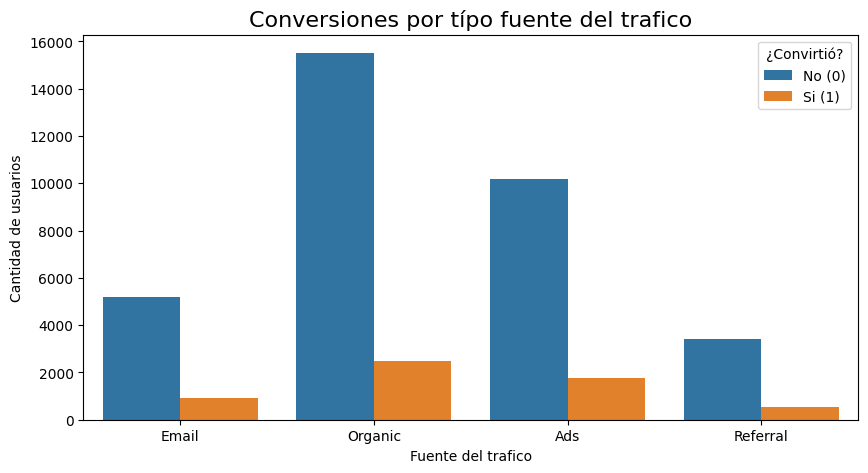

In [18]:
# Visualizaciones fuente del trafico 
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='traffic_source', hue='converted')

# Anadir detalles
plt.title('Conversiones por típo fuente del trafico', fontsize=16)
plt.xlabel('Fuente del trafico')
plt.ylabel('Cantidad de usuarios')
plt.legend(title='¿Convirtió?', labels=['No (0)', 'Si (1)'])
plt.show()


<div class="alert alert-block alert-warning">

Tu gráfico de conteo (count plot) muestra bien el volumen por canal, y tu descripción coincide con las barras. Mejoras opcionales: (1) corrige la ortografía en el título y en la etiqueta del eje: 'típo fuente del trafico' -> 'tipo de fuente de tráfico' y 'Fuente del trafico' -> 'Fuente de tráfico'; el título del siguiente gráfico también dice 'Traifco', que debería ser 'Tráfico'. (2) Este gráfico usa el azul y el naranja predeterminados de seaborn, mientras que los gráficos apilados usan azul claro y verde, y el count plot del tipo de usuario usa verde para 'No'. Usar una sola paleta en todos los gráficos, por ejemplo `palette=['#8ecae6', '#95d5b2']`, evita malinterpretar los colores; si lo cambias, actualiza las menciones de colores en tu texto.

</div>

El gráfico de barras muestra el volumen total de usuarios por fuente de tráfico (traffic_source), comparando visualmente cuántos convierten (naranja) frente a cuántos no lo hacen (azul). Desde una perspectiva de negocio, el gráfico refleja dos realidades operativas clave:   

Jerarquía en el Volumen de Adquisición: Organic se consolida como el principal motor de tráfico global (superando los 17,500 usuarios totales), seguido por Ads (~12,000 usuarios). En contraste, Email y Referral operan como canales secundarios de menor volumen.   

Proporciones Cercanas en la Conversión: A pesar de las grandes diferencias en la cantidad de usuarios que atrae cada canal, la relación visual entre los no convertidos y los convertidos luce muy similar en todos los grupos (situándose alrededor del 14% al 15%). Aunque un gráfico de conteos absolutos solo permite apreciar esta cercanía de forma visual, el análisis previo de Chi-cuadrado ($p \approx 0.034$) indica que existe una asociación estadísticamente significativa donde Ads y Email muestran tasas ligeramente superiores, pero cuya diferencia práctica es reducida. Por lo tanto, el volumen total de conversiones generadas responde principalmente a la capacidad de cada canal para atraer tráfico masivo a la plataforma.

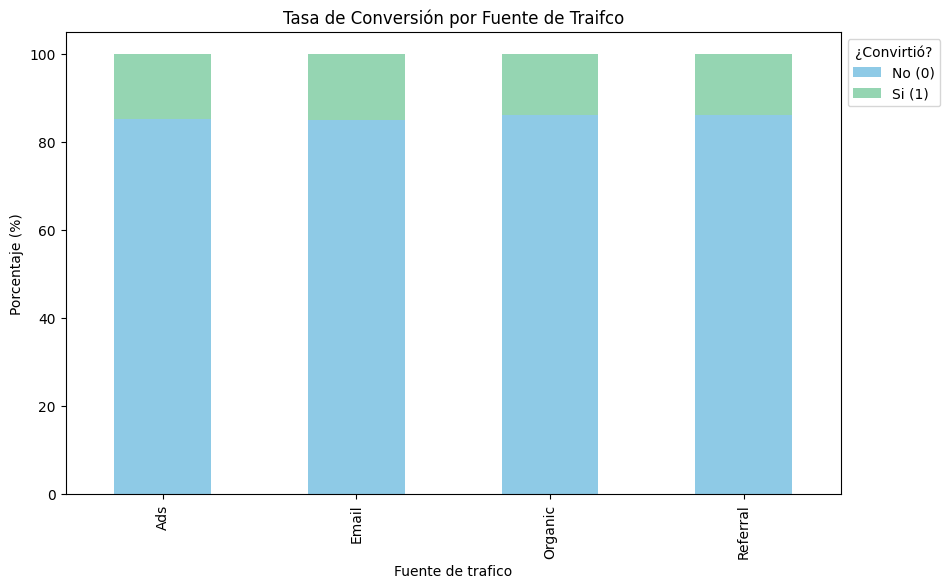

In [19]:
# Tabla de contingencia normalizada 
tabla = pd.crosstab(df['traffic_source'], df['converted'], normalize='index') * 100
tabla.plot(kind='bar', stacked=True, figsize=(10,6), color=["#8ecae6", "#95d5b2"])

plt.title('Tasa de Conversión por Fuente de Traifco')
plt.ylabel('Porcentaje (%)')
plt.xlabel('Fuente de trafico')
plt.legend(
    title='¿Convirtió?', 
    labels=['No (0)', 'Si (1)'], 
    loc='upper left', 
    bbox_to_anchor=(1,1)
)
plt.show()



El gráfico de barras apiladas al 100% muestra que las tasas de conversión son bastante similares entre todas las fuentes de tráfico, aunque presentan ligeras variaciones. Tanto Ads como Email alcanzan una conversión aproximada del 15%, superando levemente a Organic y Referral, que se sitúan alrededor del 14%.   De acuerdo con la prueba de Chi-cuadrado previa ($p = 0.034$), existe una asociación estadísticamente significativa entre el canal de origen y la conversión: Ads y Email muestran una efectividad ligeramente superior. Sin embargo, desde una perspectiva práctica, el tamaño de esta diferencia es reducido (apenas $1$ punto porcentual), lo que indica que el efecto del canal sobre la probabilidad de compra es muy leve en términos de negocio.   Dado que la brecha en eficiencia de conversión entre canales es mínima ($14\%–15\%$), el crecimiento en ventas totales sigue dependiendo principalmente del volumen bruto de tráfico que cada fuente aporta. Aunque Ads y Email convierten marginalmente mejor, la decisión sobre dónde escalar la inversión debe regirse por el Costo de Adquisición de Cliente (CAC) y el volumen total que cada canal es capaz de atraer, más que por esta pequeña ventaja porcentual.

<div class="alert alert-block alert-success">

Una lectura clara y honesta del gráfico apilado. Identificas qué canales convierten ligeramente mejor (Ads y Email), lo relacionas con el resultado de la prueba de chi-cuadrado (p = 0.034) y separas la significancia estadística del tamaño práctico ('apenas 1 punto porcentual'). Tu conclusión de que las ventas totales dependen principalmente del volumen de tráfico es coherente con los datos.

</div>

### Relación entre el tipo de usuario y la conversión

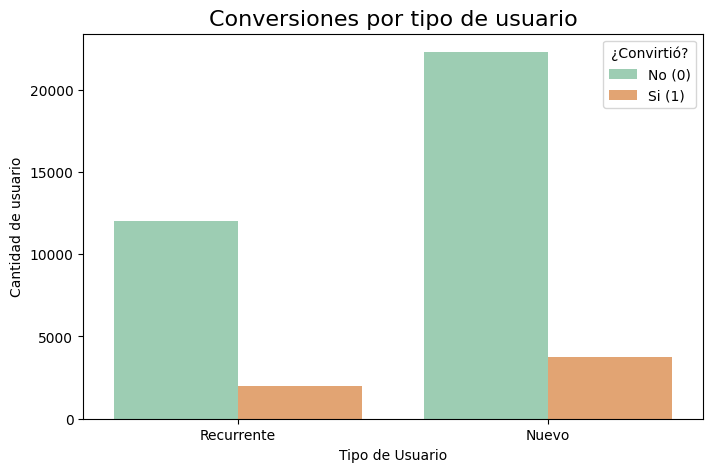

In [20]:
# Viusalización tipo de usuarui 
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='user_type', hue='converted', palette = ["#95D5B2", "#F4A261"])

# Detalles 
plt.title('Conversiones por tipo de usuario', fontsize=16)
plt.xlabel('Tipo de Usuario')
plt.ylabel('Cantidad de usuario')
plt.legend(title='¿Convirtió?', labels=['No (0)', 'Si (1)'])
plt.show()


El gráfico de barras representa el volumen absoluto de usuarios según su tipo (Recurrente vs. Nuevo) y su resultado de conversión (No (0) vs. Si (1)). Se evidencia una clara asimetría en el volumen total, donde los usuarios Nuevos casi duplican en cantidad a los usuarios Recurrentes dentro de la muestra registrada (aproximadamente $26,000$ frente a $14,000$, lo que equivale a una proporción cercana a $1.9$ a $1$).   A pesar de esta diferencia en el volumen total de usuarios, la proporción visual entre la barra verde (No convirtió) y la barra naranja (Sí convirtió) se mantiene muy similar en ambos grupos. Esto es coherente con los resultados de la prueba Chi-cuadrado previamente ejecutada ($p = 0.474$), que indica que no existe evidencia estadística suficiente para afirmar que el tipo de usuario influya en la tasa de conversión, situándose ambos segmentos alrededor del $14\%$.   El mayor aporte de conversiones totales de los usuarios Nuevos proviene puramente de su volumen bruto de captación, y no de una mayor propensión a la compra. Del mismo modo, el segmento Recurrente no muestra una ventaja significativa en la conversión por el simple hecho de haber visitado antes la plataforma. En consecuencia, la estrategia comercial no debe gastar recursos en diferenciar flujos de conversión basados únicamente en la antigüedad o recurrencia del usuario, sino en implementar tácticas transversales de optimización dentro del sitio para elevar la tasa base general por encima del $14\%$.

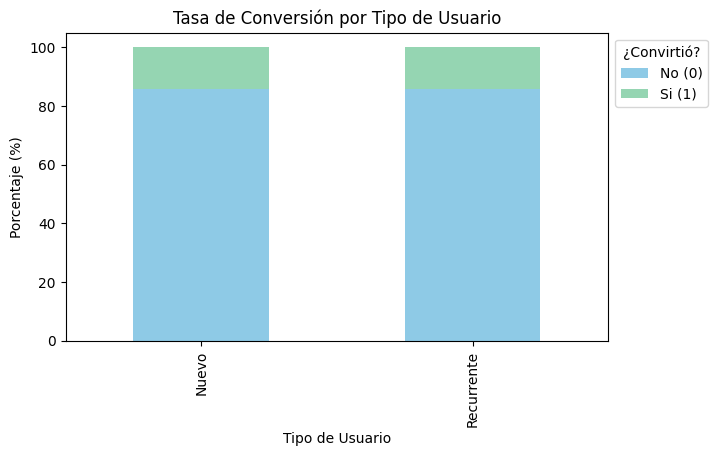

In [21]:
tabla = pd.crosstab(df['user_type'], df['converted'], normalize='index') * 100
tabla.plot(kind='bar', stacked=True, figsize=(7,4), color=["#8ecae6", "#95d5b2"])

plt.title('Tasa de Conversión por Tipo de Usuario')
plt.ylabel('Porcentaje (%)')
plt.xlabel('Tipo de Usuario')
plt.legend(
    title='¿Convirtió?', 
    labels=['No (0)', 'Si (1)'], 
    loc='upper left', 
    bbox_to_anchor=(1,1)
)
plt.show()



El gráfico de barras apiladas al 100% evalúa la tasa de conversión relativa ajustada por tipo de usuario (Nuevo vs. Recurrente), eliminando el sesgo causado por las diferencias en el volumen absoluto de tráfico entre ambos segmentos.   La proporción de conversión es prácticamente igual entre ambos perfiles: tanto los usuarios Nuevos como los Recurrentes registran una tasa de conversión aproximada del 14% (frente a un 86% que no convierte, tras redondear los valores). Esto respalda la prueba estadística previa ($p = 0.474$), indicando que no existe una brecha relevante en el comportamiento transaccional según la experiencia previa del cliente en la plataforma.   El hecho de haber visitado previamente la plataforma no parece incrementar la probabilidad de conversión del usuario recurrente. Como hipótesis de negocio a investigar en futuros análisis, valdría la pena evaluar si las iniciativas actuales de retención o remarketing requieren ajustes para lograr una mayor conversión en este segmento respecto al tráfico nuevo. Por ahora, con base en la evidencia disponible, la prioridad estratégica debe desplazarse de la segmentación por antigüedad a la optimización directa de la propuesta de valor y del embudo de pago (checkout UX), buscando elevar la tasa base general por encima del 14% de forma transversal.

<div class="alert alert-block alert-success">

Tu lectura del gráfico de barras apiladas coincide tanto con el gráfico como con el resultado de la prueba de chi-cuadrado (p = 0.474). Describes las tasas como 'prácticamente igual' tras el redondeo y planteas la idea de retención y remarketing como una hipótesis a investigar, no como algo que los datos demuestren.

</div>

## 🧩 Paso 7. Insight Ejecutivo para Stakeholders

Se traducen los hallazgos del análisis del experimento A/B en conclusiones accionables para el negocio, enfocadas en **versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario**.

**Preguntas a responder:**  
- ¿Qué página genera mayor conversión y gasto promedio?  
- ¿Qué canales de tráfico son más efectivos para generar conversiones?  
- ¿Existen diferencias significativas según el tipo de usuario?  
- ¿Qué recomendaciones se pueden tomar para optimizar la estrategia de marketing?


---


### 🌟 Insight Ejecutivo basado en el Experimento A/B


#### 🔍 **Comparación de página (A vs B)**  

**Gasto promedio por usuario que convirtió:**

- La prueba t de Welch (que no asume varianzas iguales) muestra una diferencia estadísticamente significativa en el gasto promedio por usuario convertido ($p < 0.001$, $t \approx -9.48$): $\approx \$68.75$ en la Landing B frente a $\approx \$61.09$ en la Landing A (unos $\$7.66$ más, aproximadamente $+12.5\%$).
- Esta comparación considera únicamente a los usuarios que completaron una conversión.
- Interpretación: El negocio debe evaluar no solo cuántos usuarios convierten, sino también cuánto valor generan después de la conversión. Un incremento en el ticket promedio puede tener un impacto tan importante como el aumento de la tasa de conversión.

<br>

**Tasa de conversión:** 
- La prueba Z de proporciones mostró una diferencia estadísticamente significativa entre las versiones A y B ($p \approx 3.76 \times 10^{-22}$).
- La versión B obtuvo un desempeño superior al alcanzar una tasa de conversión de aproximadamente **15.96%** frente al **12.57%** registrado en la versión A (alrededor de **+3.4 puntos porcentuales**).
- Interpretación: Si ambas páginas convirtieran por igual, sería extremadamente improbable observar una diferencia tan grande ($p \approx 3.76 \times 10^{-22}$), por lo que la evidencia respalda implementar la versión B para maximizar la cantidad de conversiones generadas por el sitio.

---

#### 📊 **Segmentación por fuente de tráfico**
- Aunque se encontró una asociación estadísticamente significativa entre la fuente de tráfico y la conversión ($p = 0.034$), las diferencias reales entre canales son mínimas: `Ads` y `Email` convierten ligeramente mejor (cerca del 15%) que `Organic` y `Referral` (cerca del 14%). `Organic` y `Ads` concentran el mayor volumen de usuarios y conversiones.
  
- **Interpretación:**
- La principal oportunidad de negocio no está en cambiar la mezcla de canales por eficiencia de conversión, sino en aumentar el volumen de tráfico proveniente de las fuentes que generan más alcance. Como seguimiento sugerido, se recomienda evaluar el Costo de Adquisición de Clientes (CAC) por canal, ya que las visualizaciones muestran que la diferencia en conversiones totales proviene principalmente del volumen de tráfico y no de una mejor capacidad de conversión por canal.
 
---

#### 📊 **Segmentación por tipo de usuario**
- No se encontró evidencia estadística de una relación entre el tipo de usuario y la conversión ($p = 0.474$). Tanto usuarios nuevos como recurrentes presentan una tasa de conversión cercana al 14%.
- **Interpretación:**
- La recurrencia del usuario no está generando una ventaja en términos de conversión. Las estrategias de optimización deberían enfocarse en mejorar la experiencia de compra, la propuesta de valor y el embudo de conversión, en lugar de diferenciar esfuerzos según la antigüedad del usuario. Las visualizaciones respaldan esta conclusión al mostrar proporciones prácticamente idénticas entre ambos segmentos.

---

Las visualizaciones usadas respaldan los resultados estadísticos de pasos anteriores. *(Nota sobre limitaciones: Este análisis abarca una sola ventana de observación de 28 días, la comparación de gasto se limita exclusivamente a usuarios convertidos y el conjunto de datos no incluye información sobre costos de adquisición).*

---

#### 💡 **Recomendaciones de negocio:** 
- La evidencia respalda implementar la versión B de la landing page, ya que supera significativamente a la versión A tanto en tasa de conversión (15.96% vs. 12.57%) como en gasto promedio por usuario convertido ($68.75 vs. $61.09).
- Priorizar la inversión en adquisición de tráfico mediante los canales con mayor volumen (especialmente Organic y Ads), sugiriendo un seguimiento posterior del costo de adquisición de clientes (CAC) y el retorno sobre la inversión (ROI).
- Complementar las pruebas A/B futuras midiendo el ingreso por usuario expuesto (conversión × gasto) y el valor de vida del cliente (LTV) para maximizar tanto conversiones como rentabilidad.
- Enfocar los esfuerzos de optimización en la experiencia de usuario, propuesta de valor y proceso de checkout, ya que el tipo de usuario no explica diferencias significativas en el comportamiento de conversión.



<div class="alert alert-block alert-warning">

Este es un resumen ejecutivo sólido. Responde cada pregunta de negocio en orden, reporta correctamente el estadístico de Welch (t ≈ -9.48), proporciona medias, tasas y diferencias, usa una redacción correcta del valor p, mantiene recomendaciones cautelosas ('la evidencia respalda implementar la versión B') e incluye una nota de limitaciones y métricas futuras razonables. Dos refinamientos opcionales: (1) la recomendación de priorizar Organic y Ads por volumen podría mencionar que Ads y Email convierten ligeramente mejor, y que se deberían revisar el CAC y el ROI por canal antes de redirigir la inversión. (2) Haz que la nota de limitaciones destaque, por ejemplo como una breve línea de 'Limitaciones' o una sublista en lugar de un paréntesis en cursiva, y anida el texto de 'Interpretación' bajo su etiqueta en las secciones de fuente de tráfico y tipo de usuario, como hiciste en la primera sección.

</div>